In [16]:
import os
import random
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

tumour_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]
immune_folders = ["CD4+_T_Cells", "CD8+_T_Cells", "B_Cells", "Stromal"]

img_width, img_height = 50, 50
batch_size = 256

def get_file_label_pairs(folders, main_label):
    file_label_pairs = []
    for folder in folders:
        files = tf.io.gfile.glob(os.path.join(folder, "*.png"))
        for f in files:
            sub_label = os.path.basename(folder)
            file_label_pairs.append((f, main_label, sub_label))
    return file_label_pairs

tumour_files = get_file_label_pairs(tumour_folders, main_label=1)
immune_files = get_file_label_pairs(immune_folders, main_label=0)

file_label_list = tumour_files + immune_files

random.shuffle(file_label_list)

def read_resize_label(file_path, main_label, sub_label):
    try:
        img = tf.io.read_file(file_path)
        img = tf.image.decode_png(img, channels=3)
        img = tf.image.resize(img, [img_width, img_height])
        img = img / 255.0
        return img.numpy(), main_label, sub_label
    except Exception as e:
        print(f"Error loading image {file_path}: {e}")
        return None

all_images = []
main_labels = []
sub_labels = []

for file_path, main_label, sub_label in file_label_list:
    result = read_resize_label(file_path, main_label, sub_label)
    if result:
        img, m_label, s_label = result
        all_images.append(img)
        main_labels.append(m_label)
        sub_labels.append(s_label)

X = np.array(all_images)
y_main = np.array(main_labels)
y_sub = np.array(sub_labels)

X_train, X_test, y_train_main, y_test_main, y_train_sub, y_test_sub = train_test_split(
    X, y_main, y_sub, test_size=0.3, random_state=seed, stratify=y_sub
)

print(f"Train set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

Loaded 124622 images successfully 🚀
Train set size: 87235
Test set size: 37387


In [3]:
from tensorflow.keras import layers, models, optimizers, backend as K

input_shape = (50, 50, 3)

def create_model(learning_rate=0.001):
    K.clear_session()
    model = models.Sequential([
        layers.Conv2D(32, (5, 5), activation=None, input_shape=input_shape),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (5, 5), activation=None),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model = create_model()

# Summary
model.summary()

# Train it 🎯
history = model.fit(
    train_ds,
    epochs=15,
    validation_data=test_ds
)

C:\Users\ssamj\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 46, 46, 32)          │           2,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 19, 19, 32)          │          25,632 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 9, 9, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 9, 9, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 2592)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       1,327,616 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             513 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,356,193 (5.17 MB)

 Trainable params: 1,356,193 (5.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 58s 163ms/step - accuracy: 0.7301 - loss: 0.5605 - val_accuracy: 0.8623 - val_loss: 0.3436
Epoch 2/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 50s 146ms/step - accuracy: 0.8581 - loss: 0.3475 - val_accuracy: 0.8664 - val_loss: 0.3243
Epoch 3/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 51s 148ms/step - accuracy: 0.8696 - loss: 0.3194 - val_accuracy: 0.8749 - val_loss: 0.3074
Epoch 4/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 48s 141ms/step - accuracy: 0.8764 - loss: 0.3035 - val_accuracy: 0.8817 - val_loss: 0.2964
Epoch 5/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 49s 143ms/step - accuracy: 0.8828 - loss: 0.2902 - val_accuracy: 0.8788 - val_loss: 0.2978
Epoch 6/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 49s 144ms/step - accuracy: 0.8885 - loss: 0.2787 - val_accuracy: 0.8818 - val_loss: 0.2937
Epoch 7/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 51s 149ms/step - accuracy: 0.8898 - loss: 0.2778 - val_accuracy: 0.8890 - val_loss: 0.2786
Epoch 8/15
341/341 ━━━━━━━━━━━━━━━━━━━━ 56s 163ms/step - accuracy: 0.8954 - loss: 0

147/147 ━━━━━━━━━━━━━━━━━━━━ 14s 94ms/step
Confusion Matrix:
[[15628  3217]
 [ 1917 16625]]


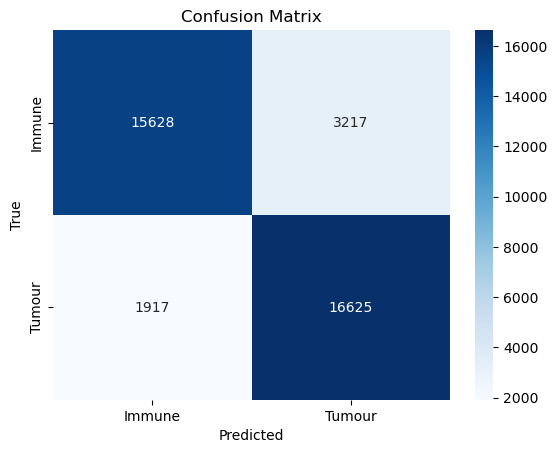

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.83      0.86     18845
           1       0.84      0.90      0.87     18542

    accuracy                           0.86     37387
   macro avg       0.86      0.86      0.86     37387
weighted avg       0.86      0.86      0.86     37387



In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(test_ds)
y_pred = (y_pred > 0.2).astype(int)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Immune", "Tumour"], yticklabels=["Immune", "Tumour"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred))

Label mapping: {'Invasive_Tumor': 0, 'DCIS_1': 1, 'DCIS_2': 2, 'Prolif_Invasive_Tumor': 3}


C:\Users\ssamj\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 46, 46, 32)          │           2,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 19, 19, 64)          │          51,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 9, 9, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 9, 9, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 5184)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         663,680 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 717,892 (2.74 MB)

 Trainable params: 717,892 (2.74 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 35s 383ms/step - accuracy: 0.5208 - loss: 1.1875 - val_accuracy: 0.5495 - val_loss: 1.0841
Epoch 2/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 33s 374ms/step - accuracy: 0.5444 - loss: 1.1038 - val_accuracy: 0.6121 - val_loss: 1.0042
Epoch 3/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 32s 368ms/step - accuracy: 0.5972 - loss: 1.0300 - val_accuracy: 0.6073 - val_loss: 0.9604
Epoch 4/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 32s 368ms/step - accuracy: 0.6166 - loss: 0.9997 - val_accuracy: 0.6805 - val_loss: 0.9074
Epoch 5/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 31s 360ms/step - accuracy: 0.6466 - loss: 0.9474 - val_accuracy: 0.5670 - val_loss: 1.0377
Epoch 6/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 31s 355ms/step - accuracy: 0.6355 - loss: 0.9534 - val_accuracy: 0.6509 - val_loss: 0.8889
Epoch 7/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 30s 347ms/step - accuracy: 0.6360 - loss: 0.9356 - val_accuracy: 0.6788 - val_loss: 0.8661
Epoch 8/25
86/86 ━━━━━━━━━━━━━━━━━━━━ 30s 349ms/step - accuracy: 0.6655 - loss: 0.8806 - val_accu

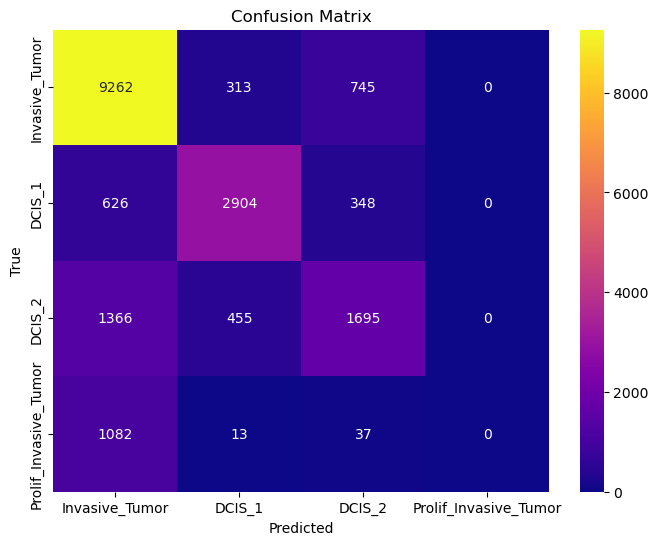


Classification Report:
                       precision    recall  f1-score   support

       Invasive_Tumor       0.75      0.90      0.82     10320
               DCIS_1       0.79      0.75      0.77      3878
               DCIS_2       0.60      0.48      0.53      3516
Prolif_Invasive_Tumor       0.00      0.00      0.00      1132

             accuracy                           0.74     18846
            macro avg       0.53      0.53      0.53     18846
         weighted avg       0.69      0.74      0.71     18846



C:\Users\ssamj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ssamj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\ssamj\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [2]:
import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

tumour_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]

img_width, img_height = 50, 50
batch_size = 512
AUTOTUNE = tf.data.AUTOTUNE

def get_file_label_pairs(folders):
    file_label_pairs = []
    label_dict = {name: idx for idx, name in enumerate(folders)}
    for folder in folders:
        files = tf.io.gfile.glob(os.path.join(folder, "*.png"))
        for f in files:
            file_label_pairs.append((f, label_dict[folder]))
    return file_label_pairs, label_dict

file_label_pairs, label_dict = get_file_label_pairs(tumour_folders)
print("Label mapping:", label_dict)

random.shuffle(file_label_pairs)

file_paths, labels = zip(*file_label_pairs)
file_paths = list(file_paths)
labels = list(labels)

train_paths, test_paths, y_train, y_test = train_test_split(
    file_paths, labels, test_size=0.3, random_state=seed, stratify=labels
)

def decode_img(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [img_width, img_height])
    img = img / 255.0
    return img

def process_path(file_path, label):
    return decode_img(file_path), label

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, y_train))
train_ds = train_ds.map(process_path, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.shuffle(buffer_size=1000).batch(batch_size).prefetch(AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, y_test))
test_ds = test_ds.map(process_path, num_parallel_calls=AUTOTUNE)
test_ds = test_ds.batch(batch_size).prefetch(AUTOTUNE)

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (5, 5), activation='relu', input_shape=(img_width, img_height, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (5, 5), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(train_ds, epochs=25, validation_data=test_ds)

loss, acc = model.evaluate(test_ds)
print(f"\nTest accuracy: {acc:.4f}")

y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_dict.keys(), yticklabels=label_dict.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_dict.keys()))

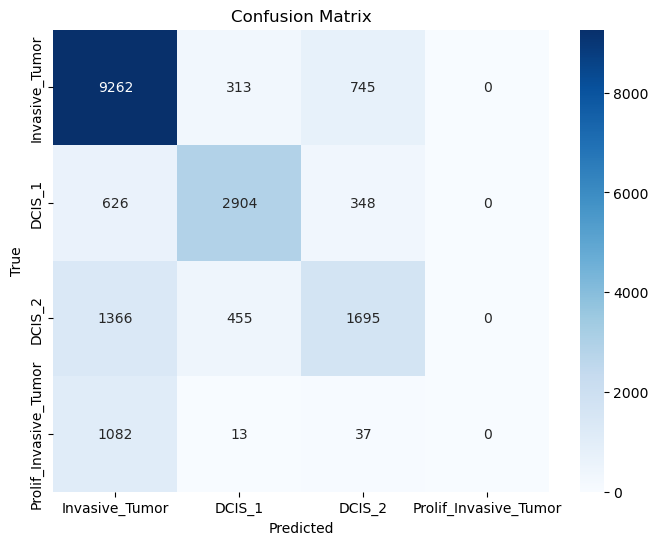

In [3]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_dict.keys(), yticklabels=label_dict.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

Epoch 1/20


C:\Users\ssamj\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


99/99 ━━━━━━━━━━━━━━━━━━━━ 34s 324ms/step - accuracy: 0.3251 - loss: 1.4844 - val_accuracy: 0.1219 - val_loss: 1.3470
Epoch 2/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 279ms/step - accuracy: 0.2886 - loss: 1.3175 - val_accuracy: 0.0870 - val_loss: 1.3559
Epoch 3/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 275ms/step - accuracy: 0.2743 - loss: 1.2703 - val_accuracy: 0.2709 - val_loss: 1.2655
Epoch 4/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 281ms/step - accuracy: 0.3056 - loss: 1.1937 - val_accuracy: 0.3215 - val_loss: 1.1615
Epoch 5/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 278ms/step - accuracy: 0.4023 - loss: 1.1167 - val_accuracy: 0.3131 - val_loss: 1.1611
Epoch 6/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 276ms/step - accuracy: 0.4144 - loss: 1.0886 - val_accuracy: 0.3403 - val_loss: 1.1065
Epoch 7/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 282ms/step - accuracy: 0.4501 - loss: 1.0524 - val_accuracy: 0.3713 - val_loss: 1.1552
Epoch 8/20
99/99 ━━━━━━━━━━━━━━━━━━━━ 28s 279ms/step - accuracy: 0.4757 - loss: 1.0368 - val_accuracy: 0.377

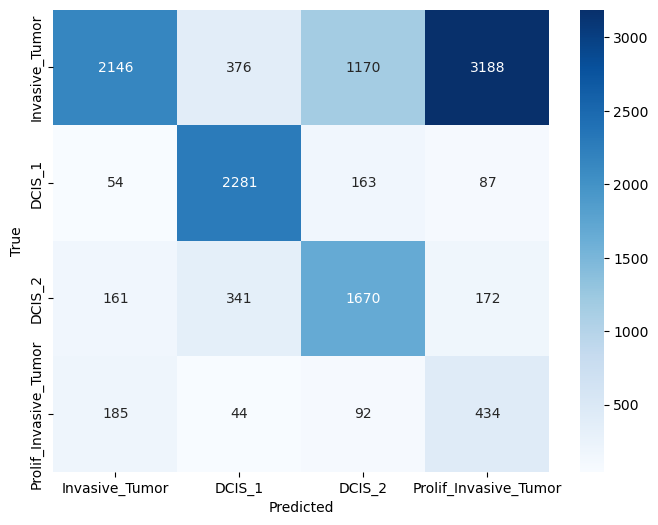

In [5]:
import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import class_weight

seed = 3888
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

tumour_folders = ["Invasive_Tumor", "DCIS_1", "DCIS_2", "Prolif_Invasive_Tumor"]

img_width, img_height = 50, 50
batch_size = 512
AUTOTUNE = tf.data.AUTOTUNE

def get_file_label_pairs(folders):
    file_label_pairs = []
    label_dict = {name: idx for idx, name in enumerate(folders)}
    for folder in folders:
        files = tf.io.gfile.glob(os.path.join(folder, "*.png"))
        for f in files:
            file_label_pairs.append((f, label_dict[folder]))
    return file_label_pairs

pairs = get_file_label_pairs(tumour_folders)
file_paths, labels = zip(*pairs)
file_paths, labels = np.array(file_paths), np.array(labels)
train_files, test_files, train_labels, test_labels = train_test_split(file_paths, labels, test_size=0.2, stratify=labels, random_state=seed)

def decode_img(img_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [img_width, img_height])
    img = img / 255.0
    return img

def process_path(file_path, label):
    img = decode_img(file_path)
    return img, label

def prepare_dataset(files, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))
    ds = ds.map(process_path, num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = prepare_dataset(train_files, train_labels, shuffle=True)
test_ds = prepare_dataset(test_files, test_labels)

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights = dict(enumerate(class_weights))

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(img_width, img_height, 3)),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2,2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(train_ds, epochs=20, validation_data=test_ds, class_weight=class_weights)

y_pred = model.predict(test_ds)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.concatenate([y for x, y in test_ds], axis=0)

print(classification_report(y_true, y_pred_classes, target_names=tumour_folders))

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=tumour_folders, yticklabels=tumour_folders)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
